In [1]:
%matplotlib inline

import random
import matplotlib.pyplot as plt
from copy import deepcopy
import numpy as np
import pystan 
import pandas as pd
import seaborn as sns
import math
import statistics as st
from matplotlib.backends.backend_pdf import PdfPages
import pickle
from tqdm.notebook import tqdm as tqdm

In [2]:
# Reduction data Import
datum = pd.read_csv('data/transportation/Static_Sal_growth_lettuce.csv')
pd.set_option('display.max_rows', None)
print(datum)

    TIME     N    N0  Temp  Unnamed: 4
0      0  4.15  4.03     5         NaN
1     12  4.03  4.03     5         NaN
2     24  4.12  4.03     5         NaN
3     36  4.21  4.03     5         NaN
4     48  4.05  4.03     5         NaN
5     60  4.28  4.03     5         NaN
6     72  4.15  4.03     5         NaN
7     84  4.25  4.03     5         NaN
8     96  4.34  4.03     5         NaN
9    120  4.26  4.03     5         NaN
10     0  4.09  4.09    10         NaN
11    12  4.32  4.09    10         NaN
12    24  4.18  4.09    10         NaN
13    36  4.25  4.09    10         NaN
14    48  4.45  4.09    10         NaN
15    60  4.69  4.09    10         NaN
16    72  4.88  4.09    10         NaN
17    84  4.98  4.09    10         NaN
18    96  5.10  4.09    10         NaN
19   120  5.00  4.09    10         NaN
20     0  4.08  3.91    15         NaN
21     2  3.93  3.91    15         NaN
22     4  3.91  3.91    15         NaN
23     6  3.93  3.91    15         NaN
24     8  4.22  3.91    1

In [3]:
#counts
S = datum.iloc[:,1]

#Time
t = datum.iloc[:,0]

#temperature
Temp = datum.iloc[:,3]

#初期菌数
I0 = datum.iloc[:,2]

#個数N
N = len(S) 

In [4]:
#dataset作る

dat_Salmonella = {'N' : N, 't' : t, 'logC' : S, 'Temp' : Temp, 'logC0' : I0}

In [5]:
model = '''
data {
    int N;  // number of measurement cell
    real t[N];  // time
    real Temp[N];  // temperature
    real logC[N];  // measured cell
    real logC0[N]; // 10-log Initial number cell
}
transformed data{
    real lnC[N];  // measured cell
    real lnC0[N]; // natural log Initial number cell
    for (i in 1:N){
        lnC[i] = log(10)*logC[i];
        lnC0[i] = log(10)*logC0[i];
    }
}
parameters {
    real <lower = -2,upper = 2>  a;
    real <lower = 0,upper = 20> b;
    real <lower = 0,upper = 1>  c;
    real <lower = 0,upper = 5>  d;
    real <lower = 0> h0;
    real <lower = 0> sigma;   // measurement errors
}

transformed parameters{
    real alpha0;
    real <lower = 0,upper = 100> lnCmax[N];
    real mumax[N];
    real <lower = 0,upper = 100> lnC_mean[N];
    real lag[N];
    real A[N];
    
    alpha0  = exp(-h0);
    for (i in 1:N){
        lnCmax[i]  = a * Temp[i] + b ;
        mumax[i] = (c * (Temp[i]-d))^2;
        lag[i]   = (-log(alpha0))/mumax[i];
        A[i]     = t[i] + (1/mumax[i])*log(exp(-mumax[i]*t[i]) + exp(log(alpha0)) - exp(-mumax[i]*t[i]+log(alpha0)));
        lnC_mean[i]    = lnC0[i] + mumax[i]*A[i] - log(1 + (exp(mumax[i]*A[i])-1)/(exp(lnCmax[i]-lnC0[i]))); //Baranyi式
    }
}
    
model{
    c ~ normal(0.033, 0.01);
    d ~ normal(4.54, 1);
    sigma ~ cauchy(0, 0.5);
    for (i in 1:N){ 
        lnC[i] ~ normal(lnC_mean[i], sigma);
    }
}

'''

sm = pystan.StanModel(model_code=model)

with open('stan_model_growth_Salmonella.pkl', 'wb') as f:

    pickle.dump(sm, f)

INFO:pystan:COMPILING THE C++ CODE FOR MODEL anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a NOW.
clang-12: warning: -Wl,-export_dynamic: 'linker' input unused [-Wunused-command-line-argument]
In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmpzplvall8/stanfit4anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a_5428886255192256924.cpp:836:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/numpy/core/include/numpy/arrayobject.h:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/numpy/core/include/numpy/ndarrayobject.h:12:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/numpy/core/include/numpy/ndarraytypes.h:1969:
/opt/anaconda3/envs/pystan/lib/python3.7/site-packages/numpy/core/include/numpy/npy_1_7_deprecated_api.h:17:2: warning: "Using deprecated NumPy API, disable it with "          "#define NPY_NO_DEPRECATED_API NPY_1_7_API_VERSION" [-W#warnings]
#warning "Using deprecated NumPy API, dis

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmpzplvall8/stanfit4anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a_5428886255192256924.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmpzplvall8/stanfit4anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a_5428886255192256924.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmpzplvall8/stanfit4anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a_5428886255192256924.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmpzplvall8/stanfit4anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a_5428886255192256924.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmpzplvall8/stanfit4anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a_5428886255192256924.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmpzplvall8/stanfit4anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a_5428886255192256924.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmpzplvall8/stanfit4anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a_5428886255192256924.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmpzplvall8/stanfit4anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a_5428886255192256924.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

In file included from /var/folders/f9/2qbwnnt53m1dp3z2wqzblq540000gn/T/tmpzplvall8/stanfit4anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a_5428886255192256924.cpp:846:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan_fit.hpp:22:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/services/diagnose/diagnose.hpp:10:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/test_gradients.hpp:7:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/src/stan/model/log_prob_grad.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/mat.hpp:4:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/stan_math/stan/math/rev/core.hpp:5:
In file included from /opt/anaconda3/envs/pystan/lib/python3.7/site-packages/pystan/stan/lib/s

148 warnings generated.
ld: warning: -pie being ignored. It is only used when linking a main executable


In [6]:
# Sampling Baysian model of gastric reduction
sm = pickle.load(open('stan_model_growth_Salmonella.pkl', 'rb'))
fit_Salmonella = sm.sampling(
    data = dat_Salmonella,
    iter = 25000+50000,
    chains = 4,
    warmup = 50000,
    thin = 10,
    seed = 1234
)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnCmax[i_0__] is -3.2442, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnC_mean[i_0__] is -inf, but must be greater than or equal to 0  (in 'unknown file name' at line 30)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnCmax[i_0__] is -0.492115, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnCmax[i_0__] is -0.984543, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

Rejecting initial value:
  Error evaluating the log probability at the initial va

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -9.99999, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -9.9999, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informati

Iteration:  7500 / 75000 [ 10%]  (Warmup)
Iteration:  7500 / 75000 [ 10%]  (Warmup)
Iteration:  7500 / 75000 [ 10%]  (Warmup)
Iteration:  7500 / 75000 [ 10%]  (Warmup)
Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)
Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (

In [7]:
print(fit_Salmonella)

Inference for Stan model: anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a.
4 chains, each with iter=75000; warmup=50000; thin=10; 
post-warmup draws per chain=2500, total post-warmup draws=10000.

               mean se_mean     sd   2.5%    25%    50%    75%  97.5%  n_eff   Rhat
a              0.23  1.6e-4   0.02   0.19   0.22   0.23   0.24   0.25   9321    1.0
b              9.15  3.3e-3   0.31   8.57   8.93   9.13   9.35   9.82   9061    1.0
c              0.04  2.1e-5 2.1e-3   0.04   0.04   0.04   0.05   0.05  10321    1.0
d              1.45  7.5e-3   0.75   0.18   0.89    1.4   1.96   3.04   9898    1.0
h0              3.2  5.6e-3   0.55   2.15   2.83   3.19   3.57   4.33   9735    1.0
sigma          0.43  3.8e-4   0.04   0.36    0.4   0.43   0.45   0.51   9901    1.0
alpha0         0.05  2.7e-4   0.03   0.01   0.03   0.04   0.06   0.12   9582    1.0
lnCmax[1]     10.28  2.5e-3   0.24   9.83  10.11  10.26  10.43  10.79   9193    1.0
lnCmax[2]     10.28  2.5e-3   0.24   9.83  10.11  1

In [8]:
with open('fit_nuts_Salmonella_growth.pkl', 'wb') as g:

    pickle.dump(fit_Salmonella, g)

/opt/anaconda3/envs/pystan/lib/python3.7/site-packages/ipykernel_launcher.py:3: UserWarning: Pickling fit objects is an experimental feature!
The relevant StanModel instance must be pickled along with this fit object.
When unpickling the StanModel must be unpickled first.
  This is separate from the ipykernel package so we can avoid doing imports until


Progress:   0%|          | 0/101 [00:00<?, ?it/s]

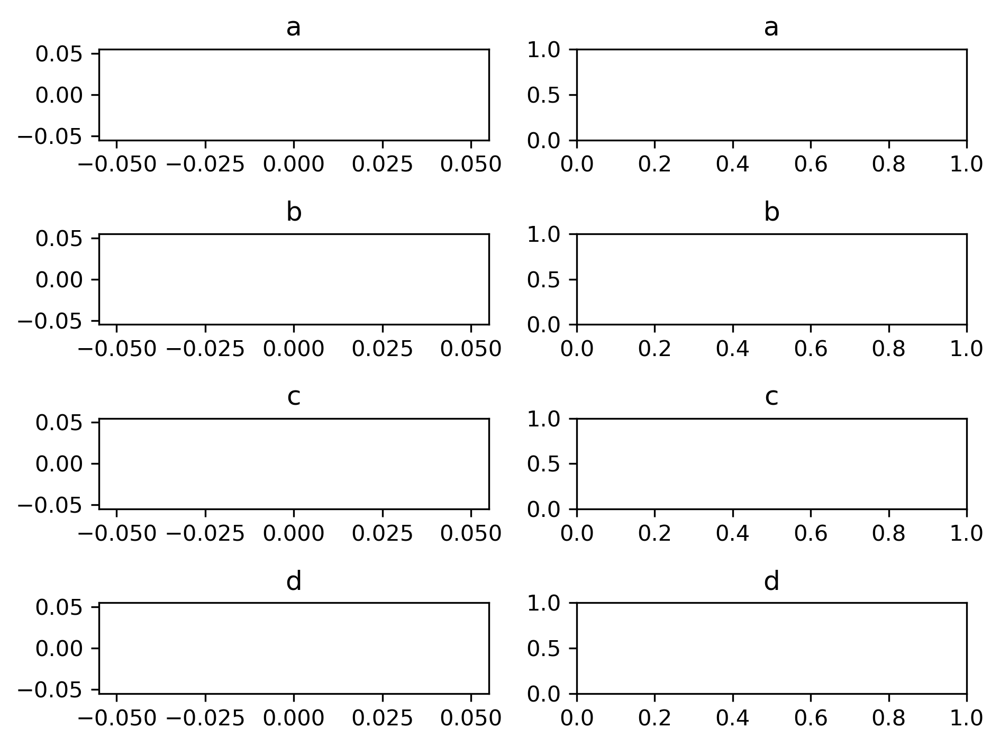

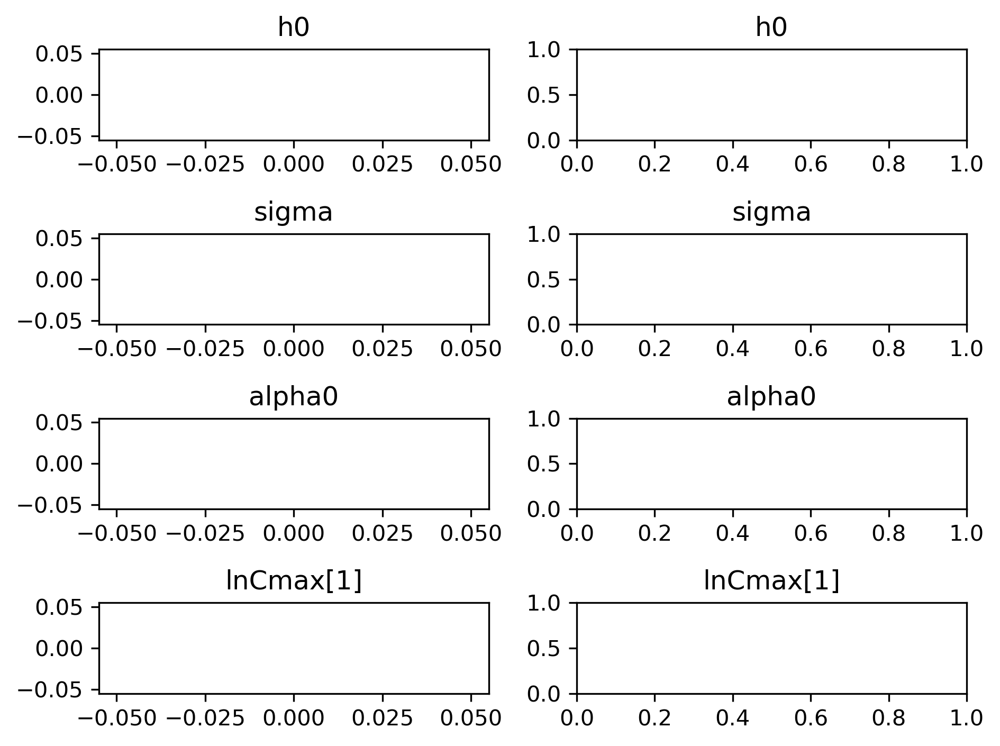

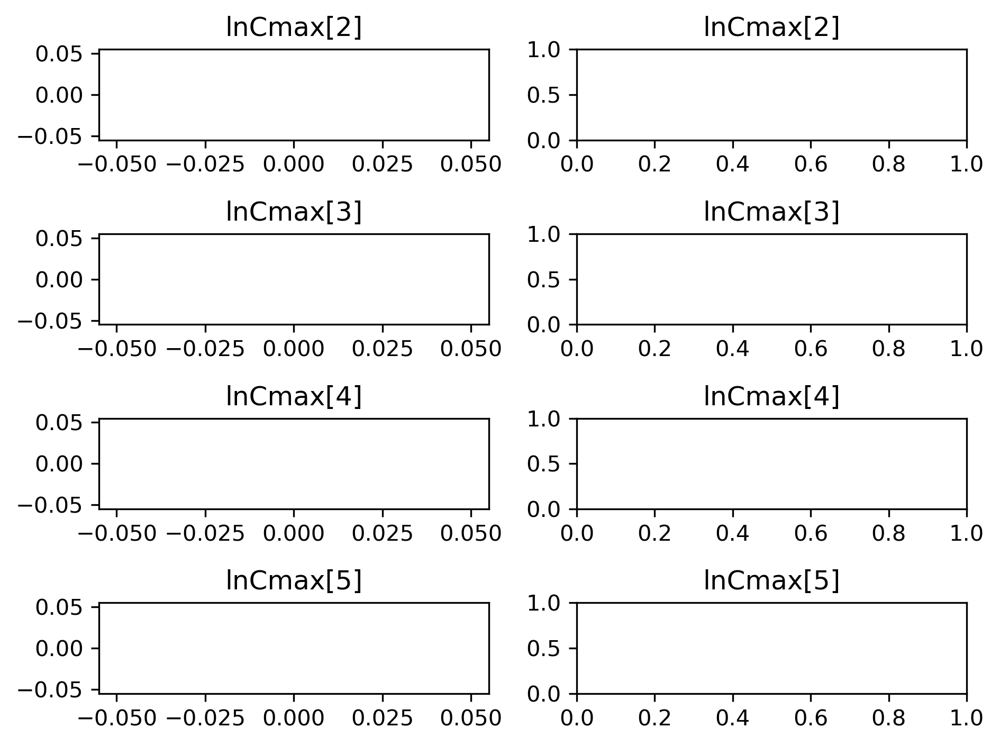

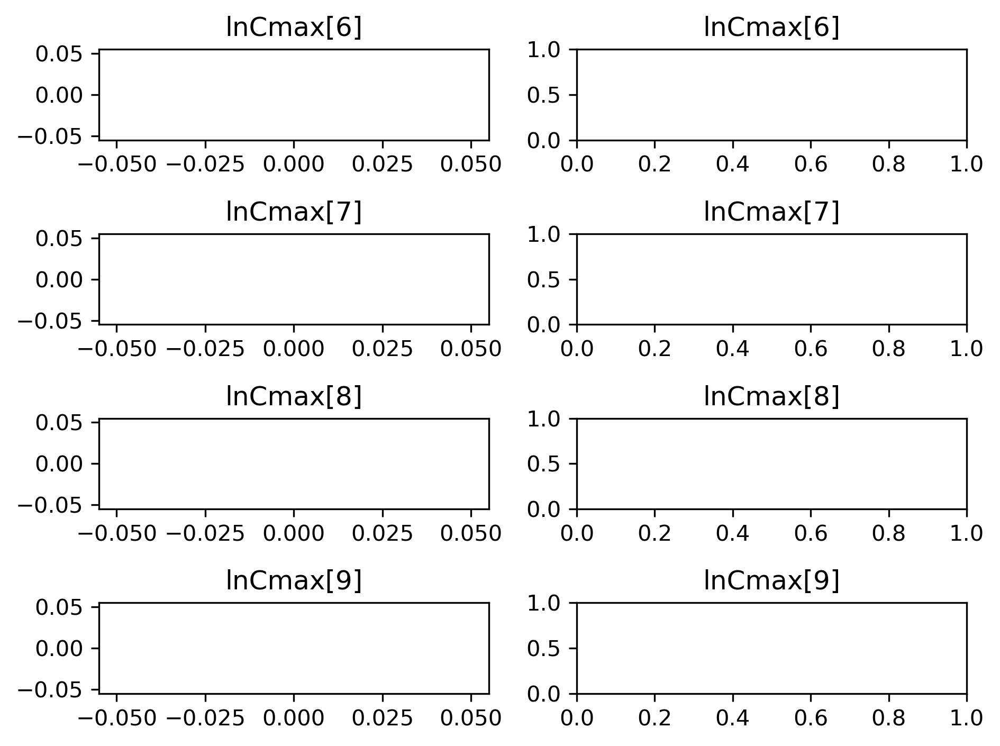

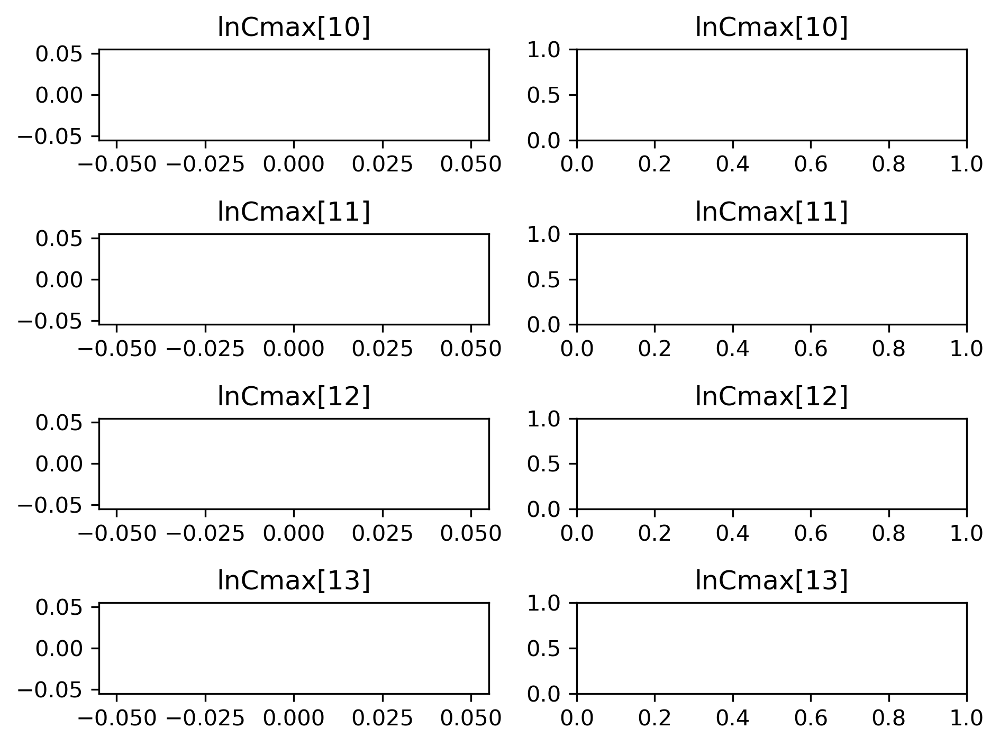

...

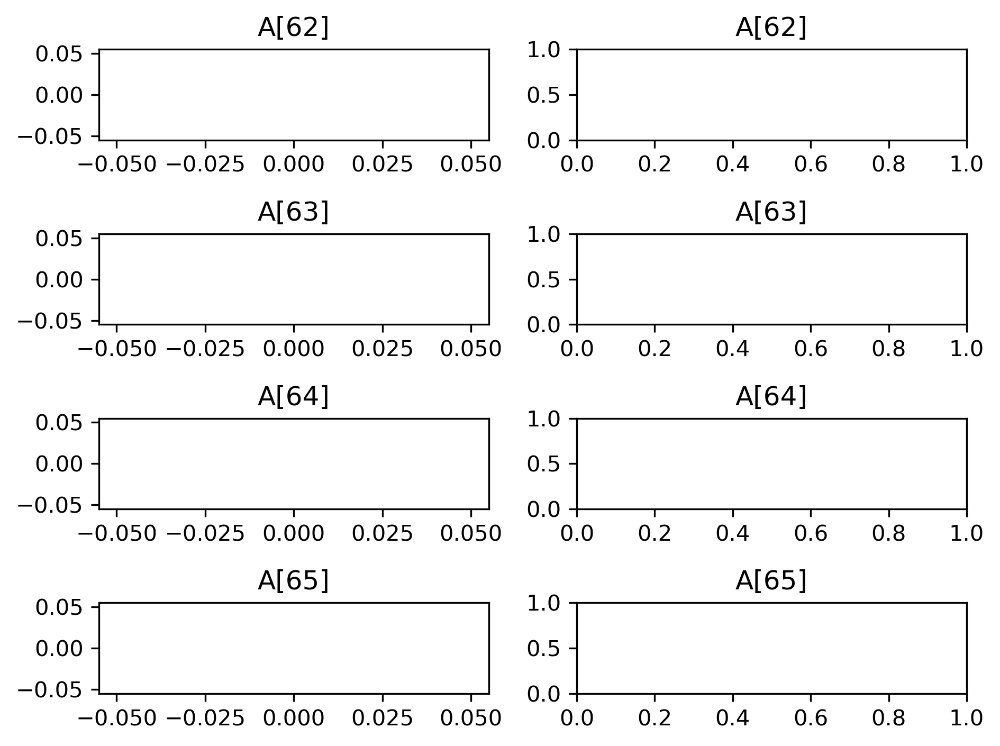

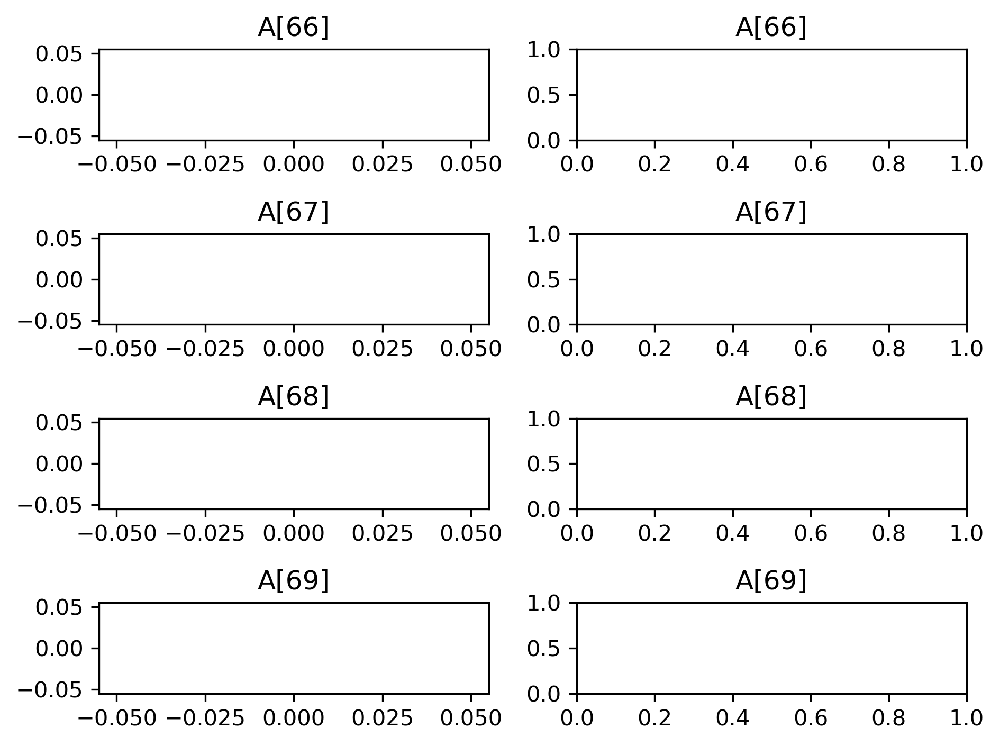

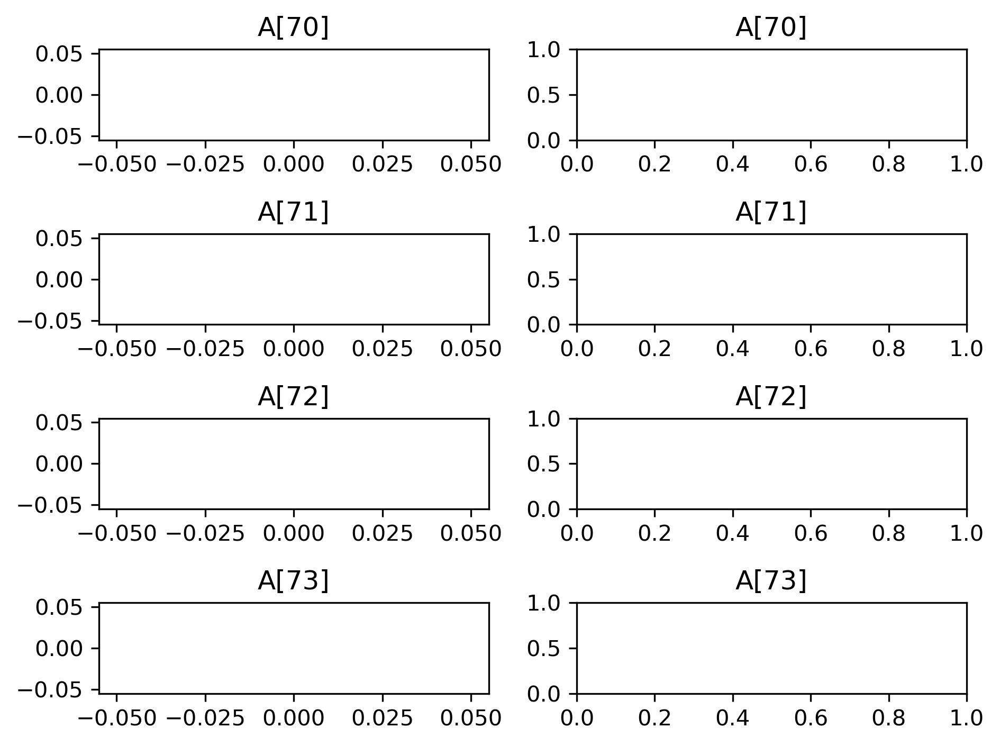

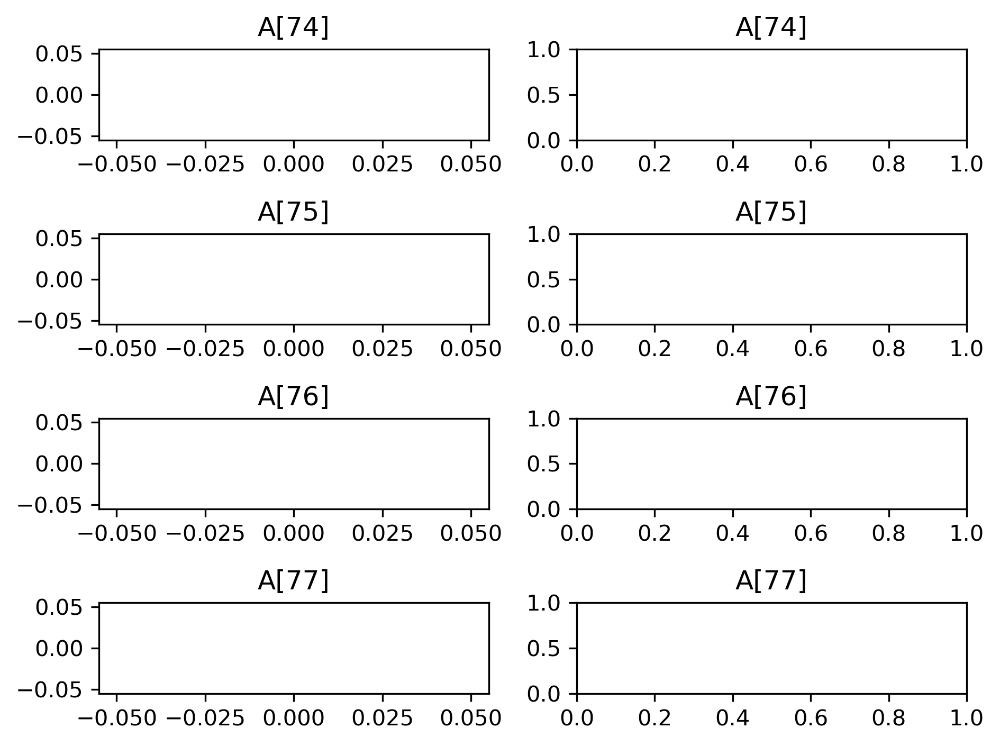

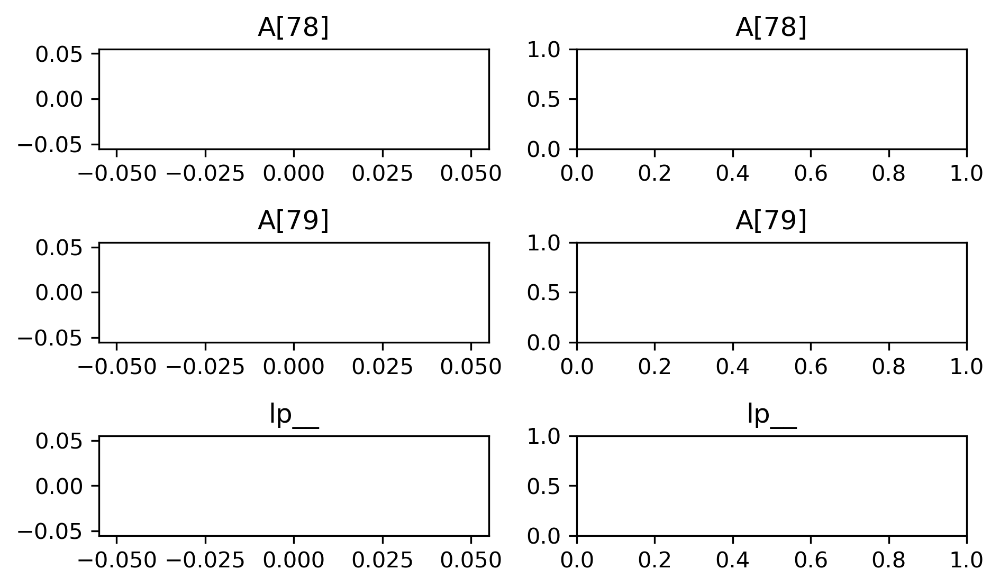

In [9]:
#計算過程を追跡する
samples = fit_Salmonella.extract(permuted = False, inc_warmup = True)
paraname = fit_Salmonella.sim["fnames_oi"]
palette = sns.color_palette()
ms = fit_Salmonella.extract(permuted=False, inc_warmup=True)
iter_from = fit_Salmonella.sim['warmup']
iter_range = np.arange(iter_from, ms.shape[0])
paraname = fit_Salmonella.sim['fnames_oi']
num_pages = math.ceil(len(paraname)/4)

#結果を何個表示するかを指定
for pg in tqdm(range(num_pages),desc='Progress', leave=False):
    plt.figure(dpi=300)
    for pos in range(4):
        pi = pg*4 + pos
        if pi >= len(paraname): break
        plt.subplot(4, 2, 2*pos+1)
        plt.tight_layout()
        [plt.plot(iter_range + 1, ms[iter_range,ci,pi], color=palette[ci]) for ci in range(ms.shape[1])]
        plt.title(paraname[pi])
        plt.subplot(4, 2, 2*(pos+1))
        plt.tight_layout()
        [sns.kdeplot(ms[iter_range,ci,pi], color=palette[ci]) for ci in range(ms.shape[1])]
        plt.title(paraname[pi])

    plt.show()

In [10]:
def Fit_Model(Temp, c, d) :
    return (c * (Temp - d))
samples = fit_Salmonella.extract(permuted=True)
temp_min = -5
temp_max = 30
devide = (temp_max-temp_min)*10
temp_interval = np.arange(temp_min, temp_max*(devide+1)/devide, 
                          (temp_max-temp_min)/devide, dtype="float")
Num_mcmc = len(samples["lp__"])
mu_conf_mcmc = np.zeros((len(temp_interval),Num_mcmc), dtype=float)
mu_conf_mcmc_quantile = np.zeros((len(temp_interval), 3), dtype=float)
mu_predict_mcmc = np.zeros((len(temp_interval),Num_mcmc), dtype=float)
mu_predict_mcmc_quantile = np.zeros((len(temp_interval), 3), dtype=float)
for j in tqdm(range(len(temp_interval)),desc='Progress', leave=False):
    for k in range(Num_mcmc):
        mu_conf_mcmc[j,k] = Fit_Model(temp_interval[j], samples["c"][k], samples["d"][k])

    mu_conf_mcmc_quantile[j,:] = np.quantile(mu_conf_mcmc[j,:],[0.025,  0.5, 0.975])

Progress:   0%|          | 0/351 [00:00<?, ?it/s]

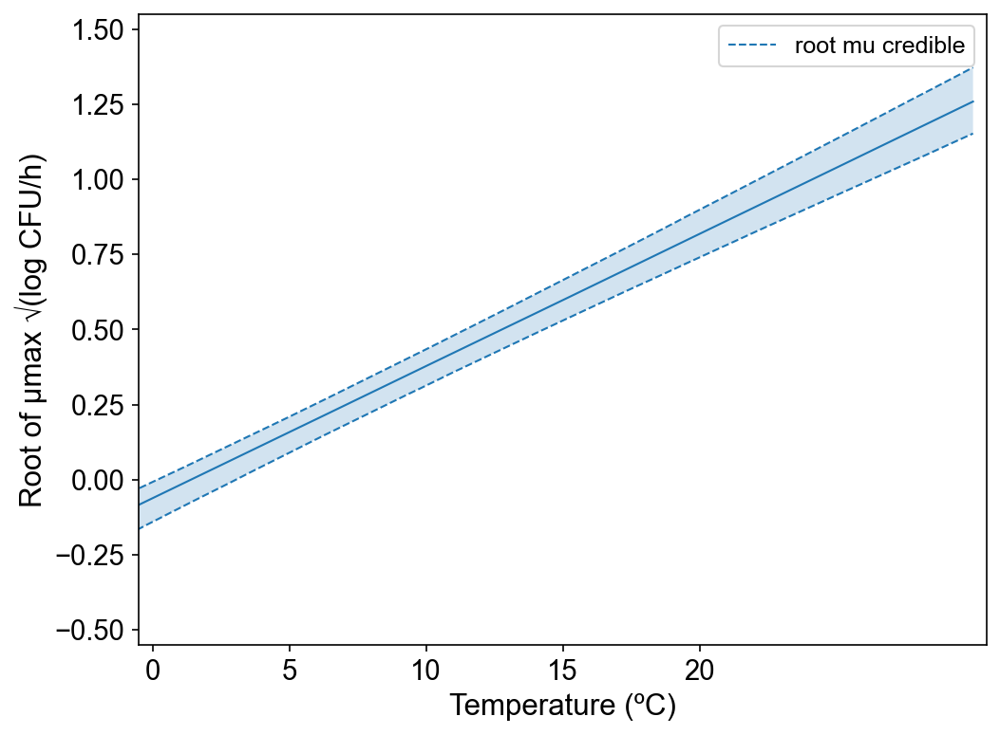

In [11]:
plt.figure(figsize=[6.4*1.2, 4.8*1.2], dpi=150)
plt.rcParams["font.family"] = "Arial"

plt.xticks(size=14)
plt.yticks(size=14)
plt.xlabel("Temperature (ºC)",size=15,fontname="Arial")
plt.ylabel("Root of µmax √(log CFU/h)",size=15,fontname="Arial")
plt.xticks(np.arange(-0, 21, 5))
plt.ylim([-0.55,1.55])
plt.xlim([-0.5,30.5])

Palette=sns.color_palette(n_colors = 3)
plt.fill_between(temp_interval, mu_conf_mcmc_quantile[:,0], mu_conf_mcmc_quantile[:,2], facecolor=Palette[0], alpha=0.2)
plt.plot(temp_interval, mu_conf_mcmc_quantile[:,0], lw=1, color=Palette[0], linestyle='--')
plt.plot(temp_interval, mu_conf_mcmc_quantile[:,2], lw=1, color=Palette[0], linestyle='--', label="root mu credible")
plt.plot(temp_interval, mu_conf_mcmc_quantile[:,1], lw=1, color=Palette[0])
plt.legend(fontsize=12)

plt.show()

In [12]:
# Reduction data Import
# Predictive Modeling for the Growth of Salmonella Enteritidis in Chicken Juice by Real-Time Polymerase Chain Reaction
datum = pd.read_csv('data/transportation/Static_Sal_growth_chicken.csv')
pd.set_option('display.max_rows', None)
print(datum)

      TIME     N    N0  Temp
0      0.0  0.32  0.32    10
1     10.7  0.55  0.32    10
2     21.4  0.55  0.32    10
3     34.9  0.98  0.32    10
4     50.4  1.45  0.32    10
5     67.9  1.45  0.32    10
6     77.8  0.55  0.32    10
7     80.3  1.45  0.32    10
8    148.8  1.45  0.32    10
9    158.8  0.98  0.32    10
10   171.5  0.98  0.32    10
11     0.0  0.35  0.35    10
12    28.9  0.98  0.35    10
13    46.6  0.48  0.35    10
14    56.7  1.45  0.35    10
15   137.3  2.26  0.35    10
16   150.0  1.45  0.35    10
17   170.1  2.40  0.35    10
18   180.0  1.88  0.35    10
19   194.5  1.66  0.35    10
20   206.9  1.15  0.35    10
21     0.0  0.39  0.39    10
22    21.4  0.98  0.39    10
23    34.9  0.98  0.39    10
24    50.4  1.45  0.39    10
25    67.9  1.31  0.39    10
26   134.3  2.26  0.39    10
27   151.5  1.45  0.39    10
28   164.0  1.66  0.39    10
29   171.5  1.45  0.39    10
30     0.0  0.76  0.76    10
31     0.4  0.55  0.76    10
32     9.3  0.55  0.76    10
33    22.8  0.

In [13]:
#counts
S = datum.iloc[:,1]

#Time
t = datum.iloc[:,0]

#temperature
Temp = datum.iloc[:,3]

#初期菌数
I0 = datum.iloc[:,2]

#個数N
N = len(S) 

In [14]:
#dataset作る

dat_Salmonella = {'N' : N, 't' : t, 'logC' : S, 'Temp' : Temp, 'logC0' : I0}

In [15]:
# Sampling Baysian model of gastric reduction
sm = pickle.load(open('stan_model_growth_Salmonella.pkl', 'rb'))
fit_Salmonella = sm.sampling(
    data = dat_Salmonella,
    iter = 25000+50000,
    chains = 4,
    warmup = 50000,
    thin = 10,
    seed = 1234
)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnC_mean[i_0__] is -inf, but must be greater than or equal to 0  (in 'unknown file name' at line 30)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnCmax[i_0__] is -6.30277, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnCmax[i_0__] is -4.5715, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnCmax[i_0__] is -1.78924, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

Rejecting initial value:
  Error evaluating the log probability at the initial valu

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnC_mean[i_0__] is -inf, but must be greater than or equal to 0  (in 'unknown file name' at line 30)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnCmax[i_0__] is -5.48591, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnCmax[i_0__] is -6.89427, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

Rejecting initial value:
  Error evaluating the log probability at the initial value.
Exception: validate transformed params: lnC_mean[i_0__] is -inf, but must be greater than or equal to 0  (in 'unknown file name' at line 30)

Rejecting initial value:
  Error evaluating the log probability at the initial value

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -20, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: validate transformed params: lnCmax[i_0__] is -20, but must be greater than or equal to 0  (in 'unknown file name' at line 28)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Mess

Iteration:  7500 / 75000 [ 10%]  (Warmup)
Iteration:  7500 / 75000 [ 10%]  (Warmup)
Iteration:  7500 / 75000 [ 10%]  (Warmup)
Iteration:  7500 / 75000 [ 10%]  (Warmup)
Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 15000 / 75000 [ 20%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 22500 / 75000 [ 30%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)
Iteration: 30000 / 75000 [ 40%]  (Warmup)
Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 37500 / 75000 [ 50%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (Warmup)
Iteration: 45000 / 75000 [ 60%]  (

To run all diagnostics call pystan.check_hmc_diagnostics(fit)


In [16]:
print(fit_Salmonella)

Inference for Stan model: anon_model_5fb1f5b3c8a231f0ef7ab2e44c15e07a.
4 chains, each with iter=75000; warmup=50000; thin=10; 
post-warmup draws per chain=2500, total post-warmup draws=10000.

                mean se_mean     sd   2.5%    25%    50%    75%  97.5%  n_eff   Rhat
a               0.62  1.6e-4   0.02   0.59   0.61   0.62   0.63   0.65   8516    1.0
b               0.11  1.1e-3   0.11 2.8e-3   0.03   0.08   0.15   0.41  10114    1.0
c               0.04  8.3e-6 8.3e-4   0.04   0.04   0.04   0.04   0.04   9964    1.0
d               4.86  1.4e-3   0.14   4.47   4.81    4.9   4.96    5.0  10064    1.0
h0              0.29  2.0e-3    0.2   0.02   0.14   0.26   0.41   0.73   9932    1.0
sigma           1.44  5.6e-4   0.06   1.33    1.4   1.44   1.47   1.55  10059    1.0
alpha0          0.76  1.4e-3   0.14   0.48   0.66   0.77   0.87   0.98  10003    1.0
lnCmax[1]       6.33  1.5e-3   0.15   6.05   6.23   6.32   6.42   6.63   9300    1.0
lnCmax[2]       6.33  1.5e-3   0.15   6.05

real <lower = -2,upper = 2>  a;   
real <lower = 0,upper = 20> b;   
real <lower = 0,upper = 1>  c;   
real <lower = 0,upper = 5>  d;   

In [17]:
with open('fit_nuts_Salmonella_growth_chicken.pkl', 'wb') as g:

    pickle.dump(fit_Salmonella, g)

/opt/anaconda3/envs/pystan/lib/python3.7/site-packages/ipykernel_launcher.py:3: UserWarning: Pickling fit objects is an experimental feature!
The relevant StanModel instance must be pickled along with this fit object.
When unpickling the StanModel must be unpickled first.
  This is separate from the ipykernel package so we can avoid doing imports until


Progress:   0%|          | 0/422 [00:00<?, ?it/s]

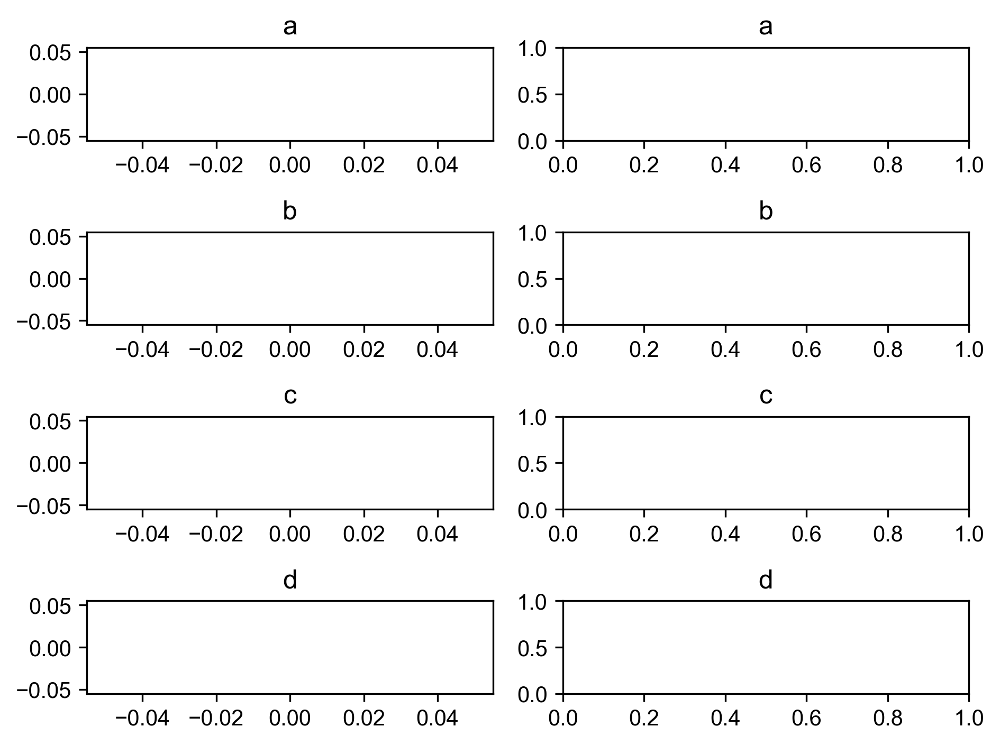

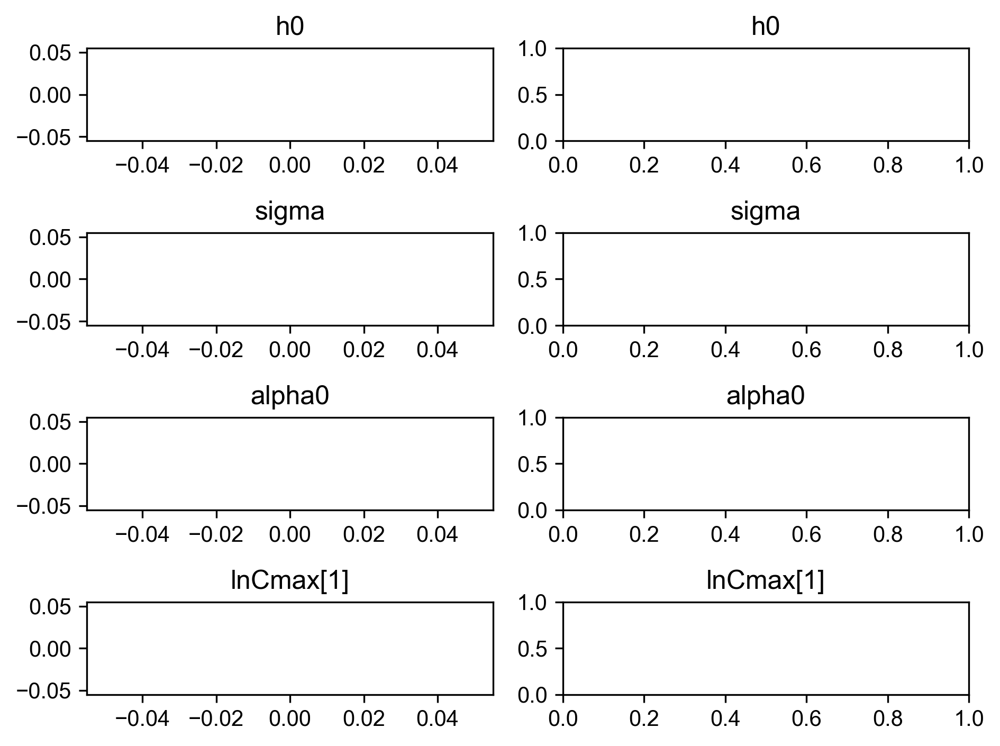

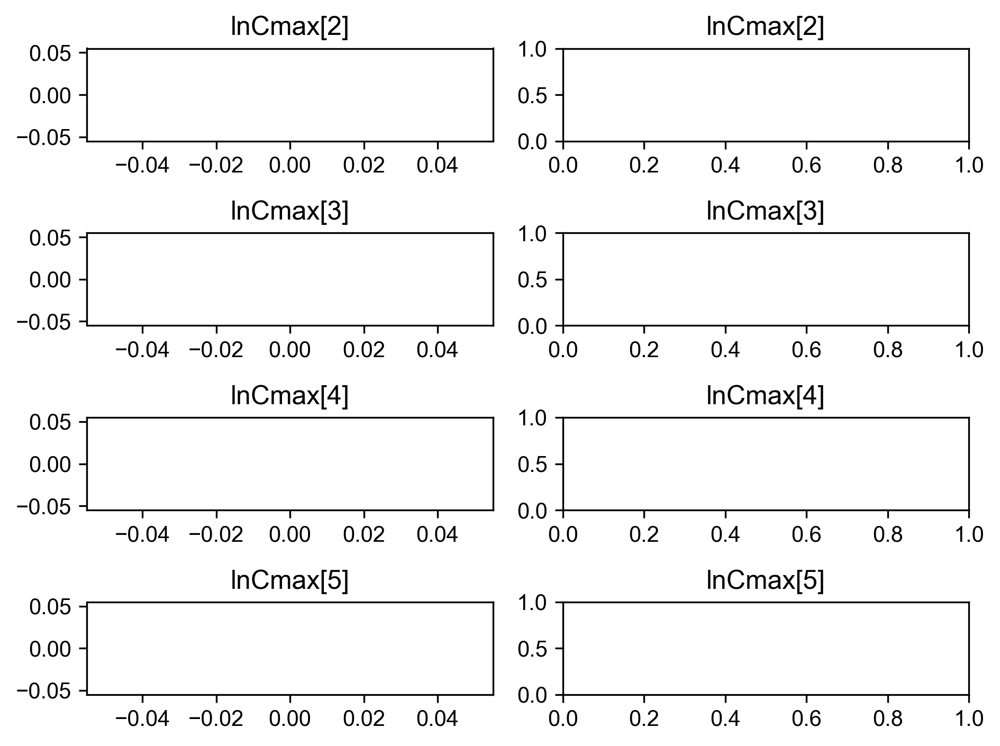

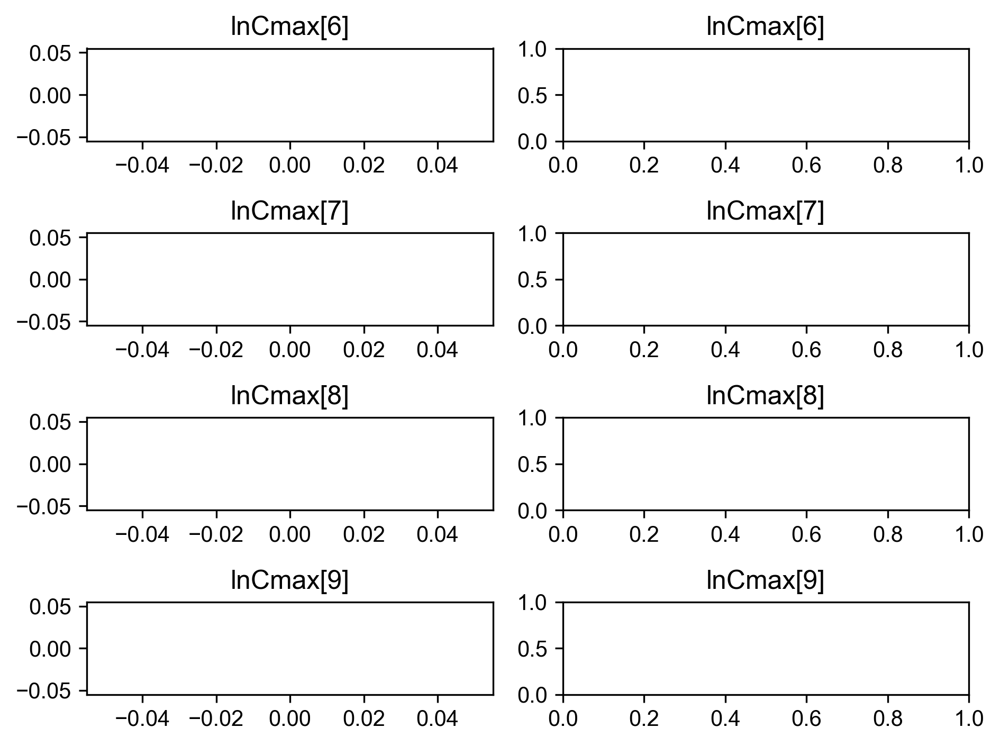

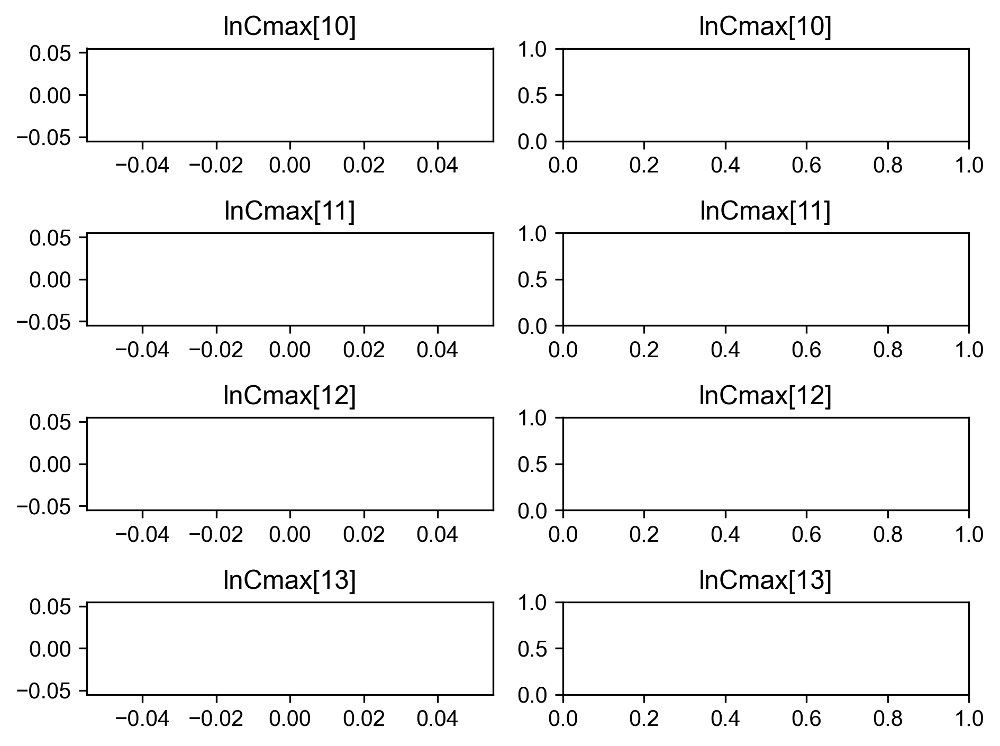

...

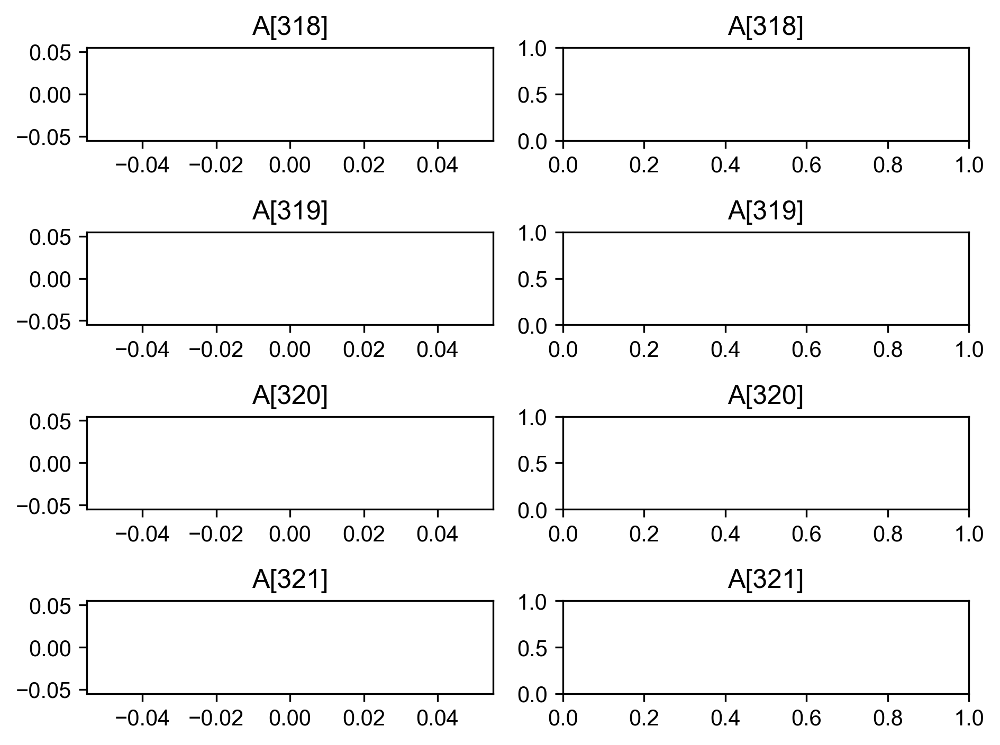

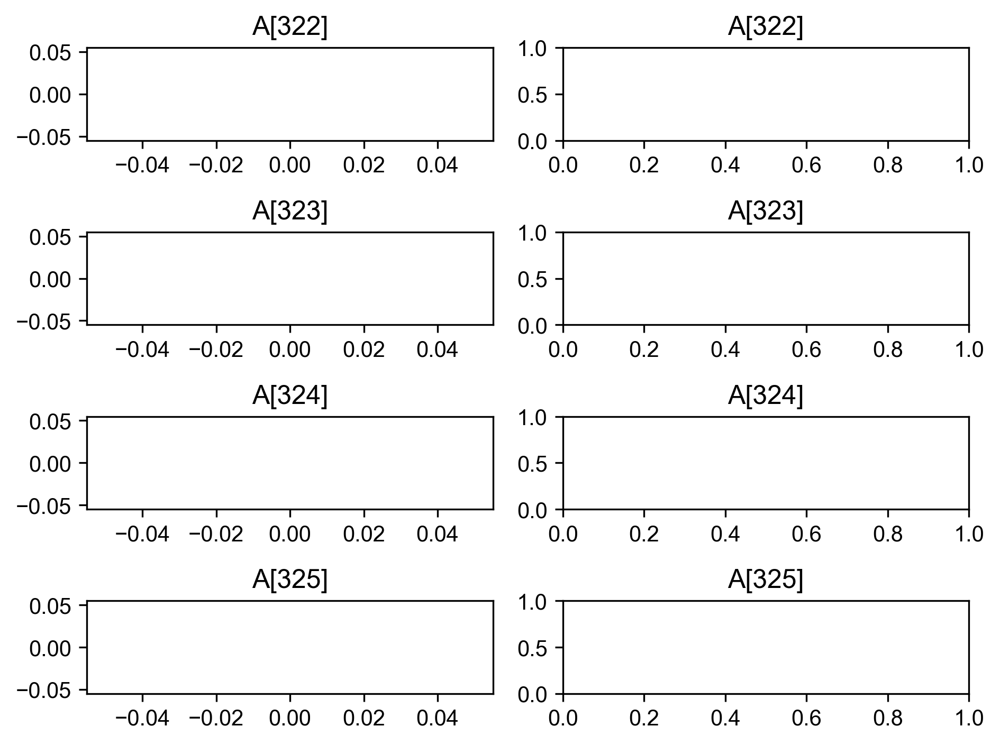

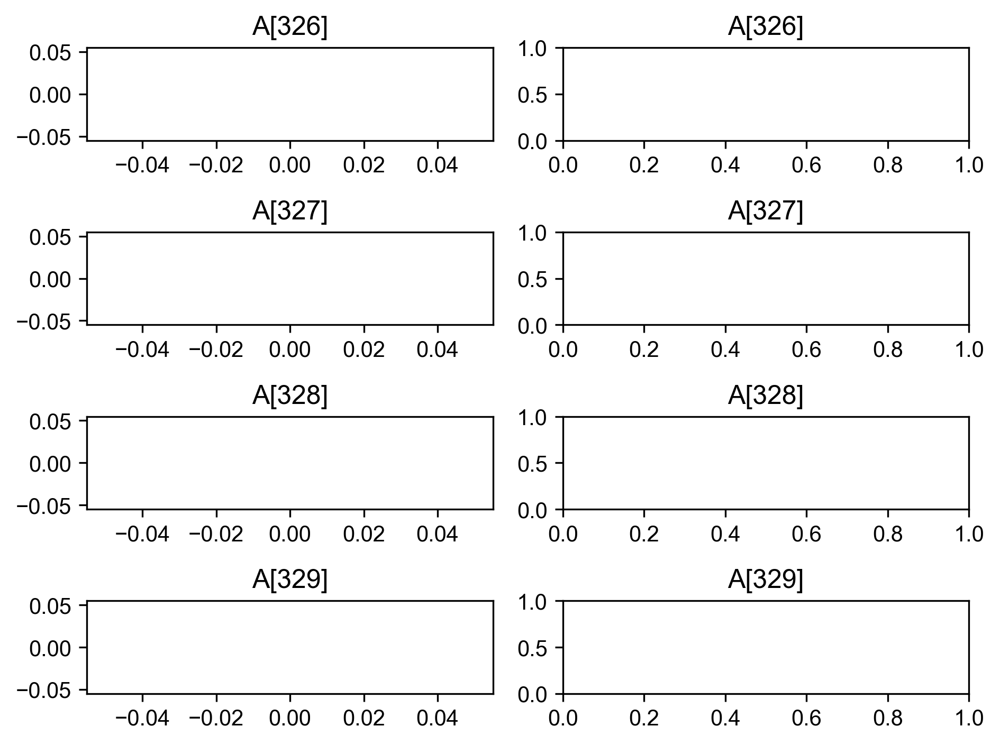

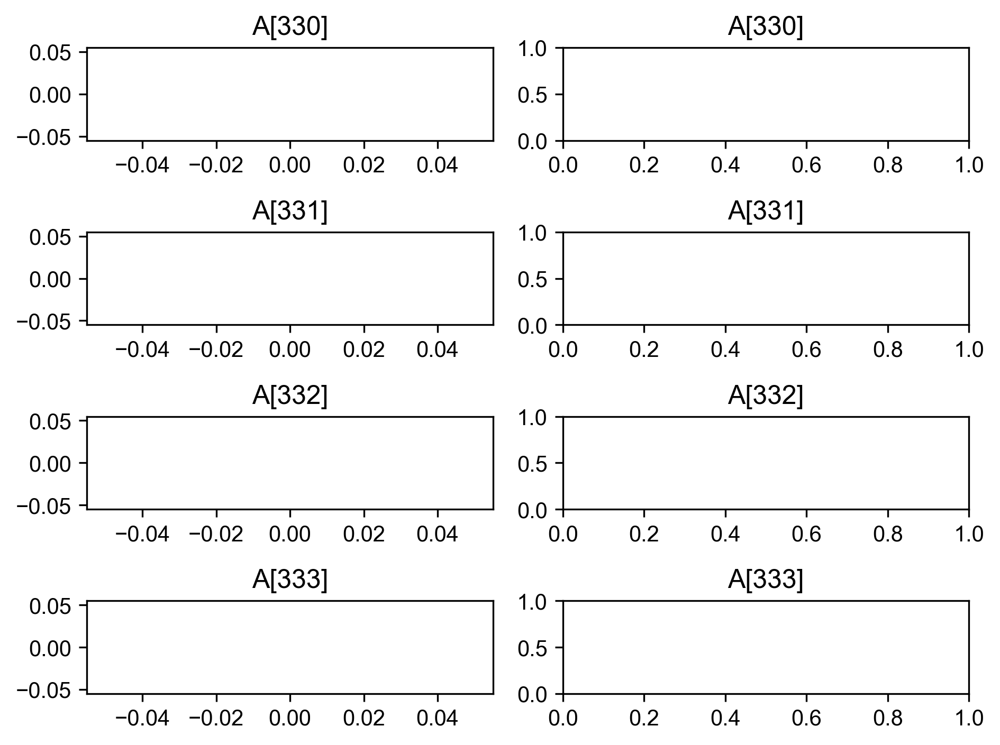

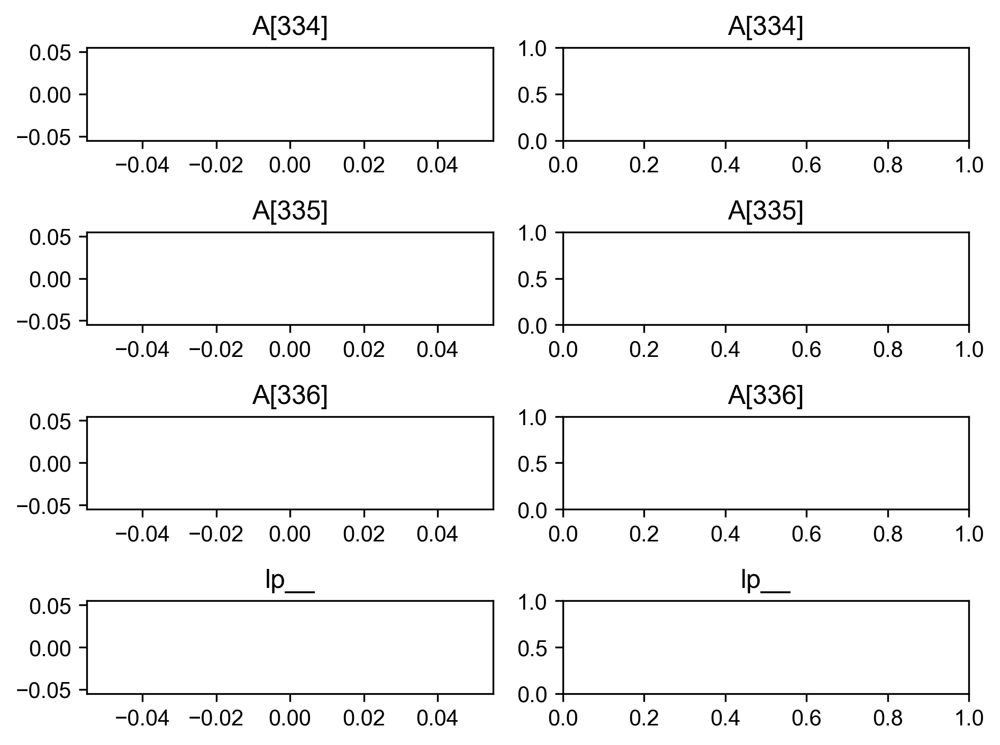

In [18]:
#計算過程を追跡する
samples = fit_Salmonella.extract(permuted = False, inc_warmup = True)
paraname = fit_Salmonella.sim["fnames_oi"]
palette = sns.color_palette()
ms = fit_Salmonella.extract(permuted=False, inc_warmup=True)
iter_from = fit_Salmonella.sim['warmup']
iter_range = np.arange(iter_from, ms.shape[0])
paraname = fit_Salmonella.sim['fnames_oi']
num_pages = math.ceil(len(paraname)/4)

#結果を何個表示するかを指定
for pg in tqdm(range(num_pages),desc='Progress', leave=False):
    plt.figure(dpi=300)
    for pos in range(4):
        pi = pg*4 + pos
        if pi >= len(paraname): break
        plt.subplot(4, 2, 2*pos+1)
        plt.tight_layout()
        [plt.plot(iter_range + 1, ms[iter_range,ci,pi], color=palette[ci]) for ci in range(ms.shape[1])]
        plt.title(paraname[pi])
        plt.subplot(4, 2, 2*(pos+1))
        plt.tight_layout()
        [sns.kdeplot(ms[iter_range,ci,pi], color=palette[ci]) for ci in range(ms.shape[1])]
        plt.title(paraname[pi])

    plt.show()

In [19]:
def Fit_Model(Temp, c, d) :
    return (c * (Temp - d))
samples = fit_Salmonella.extract(permuted=True)
temp_min = -5
temp_max = 30
devide = (temp_max-temp_min)*10
temp_interval = np.arange(temp_min, temp_max*(devide+1)/devide, 
                          (temp_max-temp_min)/devide, dtype="float")
Num_mcmc = len(samples["lp__"])
mu_conf_mcmc = np.zeros((len(temp_interval),Num_mcmc), dtype=float)
mu_conf_mcmc_quantile = np.zeros((len(temp_interval), 3), dtype=float)
mu_predict_mcmc = np.zeros((len(temp_interval),Num_mcmc), dtype=float)
mu_predict_mcmc_quantile = np.zeros((len(temp_interval), 3), dtype=float)
for j in tqdm(range(len(temp_interval)),desc='Progress', leave=False):
    for k in range(Num_mcmc):
        mu_conf_mcmc[j,k] = Fit_Model(temp_interval[j], samples["c"][k], samples["d"][k])

    mu_conf_mcmc_quantile[j,:] = np.quantile(mu_conf_mcmc[j,:],[0.025,  0.5, 0.975])

Progress:   0%|          | 0/351 [00:00<?, ?it/s]

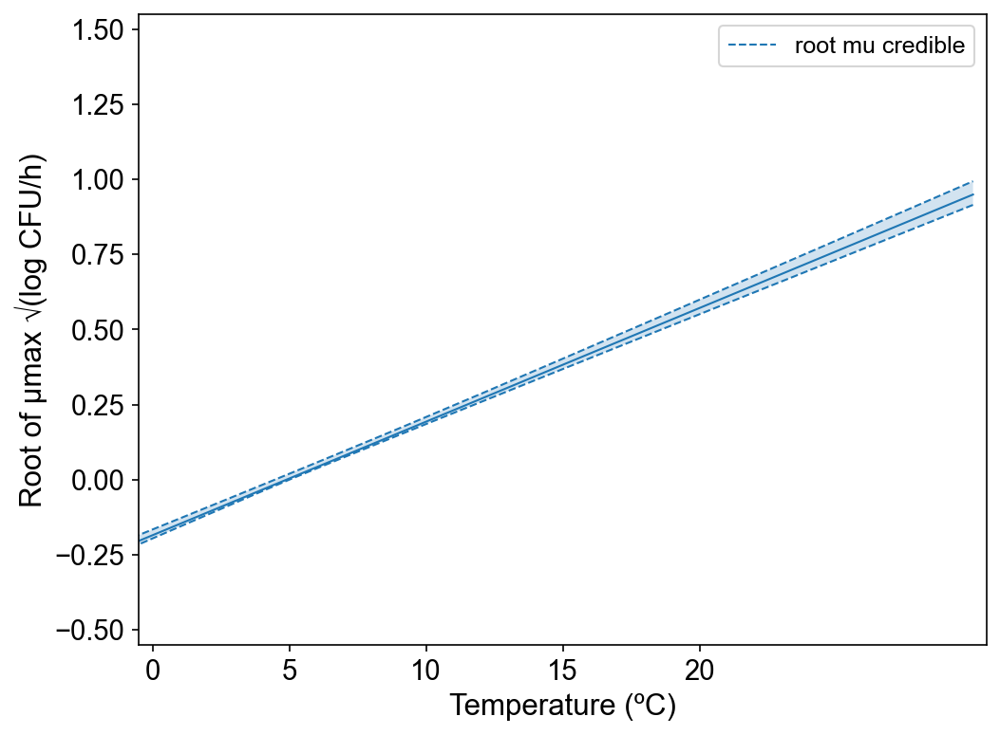

In [20]:
plt.figure(figsize=[6.4*1.2, 4.8*1.2], dpi=150)
plt.rcParams["font.family"] = "Arial"

plt.xticks(size=14)
plt.yticks(size=14)
plt.xlabel("Temperature (ºC)",size=15,fontname="Arial")
plt.ylabel("Root of µmax √(log CFU/h)",size=15,fontname="Arial")
plt.xticks(np.arange(-0, 21, 5))
plt.ylim([-0.55,1.55])
plt.xlim([-0.5,30.5])

Palette=sns.color_palette(n_colors = 3)
plt.fill_between(temp_interval, mu_conf_mcmc_quantile[:,0], mu_conf_mcmc_quantile[:,2], facecolor=Palette[0], alpha=0.2)
plt.plot(temp_interval, mu_conf_mcmc_quantile[:,0], lw=1, color=Palette[0], linestyle='--')
plt.plot(temp_interval, mu_conf_mcmc_quantile[:,2], lw=1, color=Palette[0], linestyle='--', label="root mu credible")
plt.plot(temp_interval, mu_conf_mcmc_quantile[:,1], lw=1, color=Palette[0])
plt.legend(fontsize=12)

plt.show()